<a href="https://colab.research.google.com/github/Lalsmed/ecommerce-fraud-detection/blob/main/Ecommerce_Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🛡️ Sistema de Detección de Fraude en E-commerce
**Autor:** Eduardo Medina Marmolejo  
**Objetivo:** Demostrar un ciclo completo de ciencia de datos aplicado a la prevención de fraude, desde el análisis exploratorio (SQL) hasta la evaluación financiera del modelo y la explicabilidad con SHAP.

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import xgboost as xgb
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix, average_precision_score

# 1. DATOS SIMULADOS
np.random.seed(42)
X, y_raw = make_classification(n_samples=50000, n_features=28, n_informative=15,
                               n_classes=2, weights=[0.97, 0.03], random_state=42)
df = pd.DataFrame(X, columns=[f'V{i}' for i in range(1, 29)])
df['Amount'] = np.random.lognormal(mean=3.5, sigma=1.2, size=50000).round(2)
df['Class'] = y_raw

df['payment_method'] = np.random.choice(['Credit_Card','Debit_Card','PayPal','Crypto'],
                                        size=len(df), p=[0.50,0.30,0.15,0.05])
df['device_id'] = np.random.choice([f'DEV_{i}' for i in range(5000)], size=len(df))
fraud_idx = df[df['Class']==1].index
df.loc[fraud_idx,'device_id'] = np.random.choice([f'DEV_SUSP_{i}' for i in range(20)], size=len(fraud_idx))
df['is_return'] = np.random.choice([0,1], size=len(df), p=[0.92,0.08])
df.loc[fraud_idx,'is_return'] = np.random.choice([0,1], size=len(fraud_idx), p=[0.40,0.60])
df['timestamp'] = pd.date_range('2023-01-01', periods=len(df), freq='2min')

# 2. FEATURE ENGINEERING (Sin Data Leakage)
df = df.sort_values('timestamp').reset_index(drop=True)
tmp = df.set_index('timestamp')
vel = tmp.groupby('device_id')['Amount'].rolling('1h', closed='left').count().reset_index(level=0, drop=True)
df['tx_last_1h'] = vel.reindex(tmp.index).fillna(0).astype(int).values

def hrr(g):
    s = g['is_return'].shift(1)
    return (s.expanding(min_periods=1).sum() / s.expanding(min_periods=1).count()).fillna(0)

rate = tmp.groupby('device_id').apply(hrr, include_groups=False).reset_index(level=0, drop=True)
df['hist_return_rate'] = rate.reindex(tmp.index).values

# 3. PREPARACIÓN PARA MODELOS Y SPLIT TEMPORAL
pay = pd.get_dummies(df['payment_method'], prefix='pay').astype(int)
df = pd.concat([df, pay], axis=1) # Pegamos las dummies

cols = [f'V{i}' for i in range(1,29)] + ['Amount'] + pay.columns.tolist() + ['tx_last_1h','hist_return_rate']
X_full = df[cols]
y = df['Class']

split = int(len(df)*0.8)
X_tr, X_te = X_full.iloc[:split], X_full.iloc[split:]
y_tr, y_te = y.iloc[:split], y.iloc[split:]
ratio = (y_tr==0).sum() / (y_tr==1).sum()

# 4. PREPARACIÓN PARA SQL (EDA)
conn = sqlite3.connect(':memory:')
df.to_sql('transactions', conn, index=False, if_exists='replace')

print("✅ Entorno listo: 50,000 transacciones, features creadas, split 80/20 temporal y DB SQLite conectada.")

✅ Entorno listo: 50,000 transacciones, features creadas, split 80/20 temporal y DB SQLite conectada.


## 1. Análisis Exploratorio (SQL)
Consultas para identificar patrones de riesgo en métodos de pago, dispositivos tóxicos y fraude de devoluciones.

In [2]:
print("🚀 ANÁLISIS EXPLORATORIO DE FRAUDE\n")

q1 = """
SELECT payment_method, COUNT(*) AS total_tx,
       SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END) AS fraud_count,
       ROUND(SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS fraud_rate_pct,
       ROUND(SUM(Amount), 2) AS total_volume
FROM transactions GROUP BY payment_method ORDER BY fraud_rate_pct DESC;
"""
print("--- 1. Tasa de Fraude por Método de Pago ---")
print(pd.read_sql_query(q1, conn).to_markdown(index=False), "\n")

q2 = """
SELECT device_id, COUNT(*) AS total_tx, SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END) AS fraud_count,
       ROUND(SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS fraud_rate_pct
FROM transactions WHERE Class = 1 GROUP BY device_id ORDER BY fraud_count DESC LIMIT 5;
"""
print("--- 2. Top 5 Dispositivos Más Fraudulentos ---")
print(pd.read_sql_query(q2, conn).to_markdown(index=False), "\n")

q3 = """
SELECT CASE WHEN is_return = 1 THEN 'Devolución' ELSE 'Compra Normal' END AS tipo,
       CASE WHEN Class = 1 THEN 'Fraude' ELSE 'Legítimo' END AS status,
       COUNT(*) AS cases, ROUND(AVG(Amount), 2) AS avg_ticket
FROM transactions GROUP BY 1, 2 ORDER BY tipo, status;
"""
print("--- 3. Ticket Promedio: Compras vs Devoluciones ---")
print(pd.read_sql_query(q3, conn).to_markdown(index=False))

🚀 ANÁLISIS EXPLORATORIO DE FRAUDE

--- 1. Tasa de Fraude por Método de Pago ---
| payment_method   |   total_tx |   fraud_count |   fraud_rate_pct |     total_volume |
|:-----------------|-----------:|--------------:|-----------------:|-----------------:|
| Crypto           |       2364 |            88 |             3.72 | 158287           |
| PayPal           |       7654 |           274 |             3.58 | 511445           |
| Credit_Card      |      24914 |           879 |             3.53 |      1.68656e+06 |
| Debit_Card       |      15068 |           501 |             3.32 |      1.03351e+06 | 

--- 2. Top 5 Dispositivos Más Fraudulentos ---
| device_id   |   total_tx |   fraud_count |   fraud_rate_pct |
|:------------|-----------:|--------------:|-----------------:|
| DEV_SUSP_15 |        105 |           105 |              100 |
| DEV_SUSP_9  |         97 |            97 |              100 |
| DEV_SUSP_7  |         97 |            97 |              100 |
| DEV_SUSP_6  |        

## 2. Modelado Avanzado y Comparativa
Entrenamiento de XGBoost y LightGBM con `scale_pos_weight` para manejar el desbalance de clases. Evaluación con umbral de negocio 0.1.

In [3]:
# Entrenar XGBoost
mdl_xgb = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                            scale_pos_weight=ratio, eval_metric='logloss',
                            random_state=42, n_jobs=-1)
mdl_xgb.fit(X_tr, y_tr)

# Entrenar LightGBM
mdl_lgb = lgb.LGBMClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                             scale_pos_weight=ratio, random_state=42, n_jobs=-1, verbose=-1)
mdl_lgb.fit(X_tr, y_tr)

def evaluar(mdl, nombre):
    prob = mdl.predict_proba(X_te)[:, 1]
    pred = (prob >= 0.1).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    prauc = average_precision_score(y_te, prob)
    print(f"{nombre} | PR-AUC: {prauc:.4f} | Recall: {tp/(tp+fn):.3f} | Precision: {tp/(tp+fp):.3f} | FP: {fp}")

print("--- Comparativa de modelos (Umbral de negocio = 0.1) ---")
evaluar(mdl_xgb, "XGBoost  ")
evaluar(mdl_lgb, "LightGBM ")

--- Comparativa de modelos (Umbral de negocio = 0.1) ---
XGBoost   | PR-AUC: 0.9992 | Recall: 1.000 | Precision: 0.811 | FP: 87
LightGBM  | PR-AUC: 0.9992 | Recall: 1.000 | Precision: 0.801 | FP: 93


## 3. Explicabilidad del Modelo (SHAP)
Análisis de la contribución de cada feature a las predicciones individuales, crucial para auditorías y derecho a explicación.

Generando gráfico Beeswarm (Importancia global con dirección)...


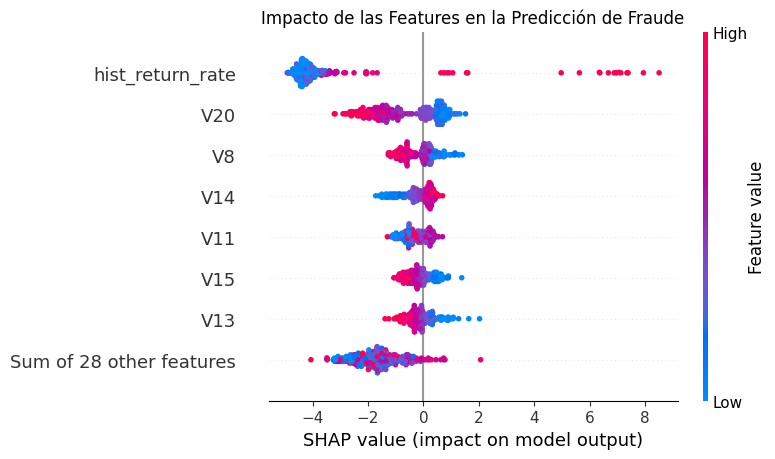

In [4]:
explainer = shap.TreeExplainer(mdl_xgb)
muestra = X_te.sample(300, random_state=42)
shap_values = explainer(muestra)

print("Generando gráfico Beeswarm (Importancia global con dirección)...")
shap.plots.beeswarm(shap_values, max_display=8, show=False)
plt.title("Impacto de las Features en la Predicción de Fraude")
plt.tight_layout()
plt.show()

## 4. Feature Selection (Trade-off de Negocio)
Evaluación del impacto de simplificar el modelo: ¿Vale la pena reducir las features a cambio de un ligero aumento en Falsos Positivos?

In [5]:
importancia = pd.Series(mdl_xgb.feature_importances_, index=X_full.columns).sort_values(ascending=False)
top5v = [f for f in importancia.index if f.startswith('V')][:5]

def dieta(features, nombre):
    m = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                          scale_pos_weight=ratio, eval_metric='logloss', random_state=42, n_jobs=-1)
    m.fit(X_tr[features], y_tr)
    prob = m.predict_proba(X_te[features])[:, 1]
    prauc = average_precision_score(y_te, prob)
    pred = (prob >= 0.1).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    print(f"{nombre} ({len(features):2d} feat) | PR-AUC: {prauc:.4f} | Recall: {tp/(tp+fn):.3f} | Precision: {tp/(tp+fp):.3f} | FP: {fp}")

print("--- Comparativa: ¿cuánto cuesta simplificar el modelo? ---")
dieta(X_full.columns.tolist(), "Completo       ")
dieta(top5v + ['tx_last_1h','hist_return_rate','Amount'], "Top 5 V + comp.  ")
dieta(['tx_last_1h','hist_return_rate','Amount'], "Solo 3 features  ")

--- Comparativa: ¿cuánto cuesta simplificar el modelo? ---
Completo        (35 feat) | PR-AUC: 0.9992 | Recall: 1.000 | Precision: 0.811 | FP: 87
Top 5 V + comp.   ( 8 feat) | PR-AUC: 0.9982 | Recall: 1.000 | Precision: 0.475 | FP: 414
Solo 3 features   ( 3 feat) | PR-AUC: 0.9970 | Recall: 1.000 | Precision: 0.334 | FP: 746


## 5. Conclusión de Negocio
El modelo completo (35 features) es el elegido para producción. Aunque es más complejo de mantener, reduce los Falsos Positivos de 746 a 87, ahorrando costos operativos significativos sin sacrificar ni un solo fraude detectado (Recall = 1.0). La simplicidad del modelo de 3 features no justifica el daño reputacional y operativo de 746 falsos positivos.